# Equity Tail Risk: VaR, Backtesting & Simulation
**MATH 60231 — Financial Econometrics | Homework 1**

**Hartanto Hartanto** (11377856) · **Elie Dominguez Dahan** (11373209) · **Guohuan Yu** (11383586)

**Stocks:** Emerson Electric (EMR), Hess (HES), General Motors (GM)  
**Market:** CRSP value-weighted total-return index (INDNO 1000200)  
**Period:** December 2, 2013 – December 2, 2022 (2,268 trading days)

**Run:** Open the `Equity_Tail_Risk` folder in VS Code, select a Python kernel, and click **Run All**. The first cell installs missing libraries when internet access is available. See `ReadMe/README.md` for details.

## Data and stock selection

We use daily CRSP total returns for the three stocks and the value-weighted market benchmark. Both CSVs accompany this notebook; the observations are aligned by date before the analysis.

In [1]:
# Install the libraries in the selected Python kernel only if necessary.
# On a fresh Python installation this step requires internet access.
import importlib.util
import subprocess
import sys

packages = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'scipy': 'scipy',
    'statsmodels': 'statsmodels',
    'IPython': 'ipython',
}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    print('Installing Python libraries: ' + ', '.join(missing))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install',
                           '--disable-pip-version-check', *missing])
    importlib.invalidate_caches()


In [2]:
from pathlib import Path
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm
import statsmodels.api as sm
from statsmodels.regression.linear_model import RegressionResults, RegressionResultsWrapper
from IPython.display import display

SEED = 60231

# Both inputs are packaged alongside this notebook. VS Code/Jupyter normally uses
# the notebook's folder as the working directory; checking parent folders also
# allows execution from a workspace opened immediately above that folder.
def find_project_folder():
    here = Path.cwd().resolve()
    # Jupyter may start in the notebook folder or in its containing workspace.
    for folder in (here, *here.parents):
        for root in (folder, folder / 'Equity_Tail_Risk'):
            data = root / 'Data' / 'Raw'
            if (data / 'crsp_stocks_raw.csv').is_file() and (data / 'crsp_market_raw.csv').is_file():
                return root
    raise FileNotFoundError(
        'CRSP CSVs not found. Keep the complete project folder together, then open the '
        'Equity_Tail_Risk folder in VS Code before running the notebook.'
    )

ROOT = find_project_folder()
STOCK_FILE = ROOT / 'Data' / 'Raw' / 'crsp_stocks_raw.csv'
MARKET_FILE = ROOT / 'Data' / 'Raw' / 'crsp_market_raw.csv'
FIG_DIR = ROOT / 'outputs' / 'figures'
TAB_DIR = ROOT / 'outputs' / 'tables'
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.float_format', lambda x: f'{x:,.6f}')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 100)
plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.2,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Stock input: Data/Raw/crsp_stocks_raw.csv')
print('Market input: Data/Raw/crsp_market_raw.csv')


Stock input: Data/Raw/crsp_stocks_raw.csv
Market input: Data/Raw/crsp_market_raw.csv


### CRSP return series

We use stock returns (`DlyRet`) and the value-weighted market's `DlyTotRet` (INDNO 1000200). Both are total-return series including distributions.

In [3]:
stocks_raw = pd.read_csv(STOCK_FILE)
market_raw = pd.read_csv(MARKET_FILE)
stocks_raw['DlyCalDt'] = pd.to_datetime(stocks_raw['DlyCalDt'])
market_raw['dlycaldt'] = pd.to_datetime(market_raw['dlycaldt'])

# CIZ index extracts identify the requested series in _name_; the numeric values are in col1.
assert market_raw['_name_'].eq('DlyTotRet').all()
assert market_raw['indno'].eq(1000200).all()
assert 'col1' in market_raw.columns, 'The CRSP market extract must include (col1) Value.'
assert set(stocks_raw['Ticker'].unique()) == {'EMR','HES','GM'}

start_date = pd.Timestamp('2013-12-02')
end_date = pd.Timestamp('2022-12-02')
assert stocks_raw['DlyCalDt'].min() == start_date and stocks_raw['DlyCalDt'].max() == end_date
assert market_raw['dlycaldt'].min() == start_date and market_raw['dlycaldt'].max() == end_date
assert not stocks_raw.duplicated(['PERMNO','DlyCalDt']).any()
assert not market_raw.duplicated(['indno','dlycaldt']).any()
assert stocks_raw['DlyRet'].notna().all() and market_raw['col1'].notna().all()

stock_wide = stocks_raw.pivot(index='DlyCalDt', columns='Ticker', values='DlyRet').sort_index()
market = market_raw.set_index('dlycaldt')['col1'].rename('MKT')
returns = stock_wide.join(market, how='inner')[['MKT','EMR','HES','GM']]
assert returns.shape == (2268,4) and not returns.isna().any().any()
assert stock_wide.shape == (2268,3), 'Each stock must cover every trading day.'
assert market_raw['dlycaldt'].nunique() == 2268
assert (stocks_raw.groupby('Ticker')['DlyCalDt'].nunique() == 2268).all()
assert stocks_raw['PERMNO'].nunique() == 3
assert returns.index.is_monotonic_increasing and returns.index.is_unique
assert np.isfinite(returns.to_numpy()).all()


validation = pd.DataFrame({
    'N': [returns[c].size for c in returns],
    'Start': [returns.index.min().date()]*4,
    'End': [returns.index.max().date()]*4,
    'Missing': [returns[c].isna().sum() for c in returns]
}, index=returns.columns)
validation.index.name='Series'
display(validation)

,N,Start,End,Missing
Series,,,,
MKT,2268,2013-12-02,2022-12-02,0
EMR,2268,2013-12-02,2022-12-02,0
HES,2268,2013-12-02,2022-12-02,0
GM,2268,2013-12-02,2022-12-02,0


### Stock characteristics

We selected EMR (Industrials), HES (Energy), and GM (Consumer Discretionary), matching Elie, Hartanto, and Guohuan's initials. The energy exposure makes HES a useful stock for studying the March 2020 market shock.

In [4]:
extreme_rows=[]
for ticker in ['EMR','HES','GM']:
    x=returns[ticker]
    extreme_rows.append({
        'Ticker': ticker,
        'Min date': x.idxmin().date(), 'Min return': x.min(),
        'Max date': x.idxmax().date(), 'Max return': x.max(),
        'Max absolute return': max(abs(x.min()),abs(x.max()))
    })
extreme_table=pd.DataFrame(extreme_rows).set_index('Ticker')
extreme_table.to_csv(TAB_DIR/'stock_extremes.csv')
display(extreme_table)
HES_EXTREME_DATE = returns['HES'].idxmin()
HES_EXTREME_RETURN = returns.loc[HES_EXTREME_DATE,'HES']
print(f'HES extreme event: {HES_EXTREME_DATE.date()}, return = {HES_EXTREME_RETURN:.6%}')

,Min date,Min return,Max date,Max return,Max absolute return
Ticker,,,,,
EMR,2020-03-09,-0.189572,2020-03-24,0.163340,0.189572
HES,2020-03-09,-0.336685,2020-03-10,0.203153,0.336685
GM,2020-03-18,-0.173228,2020-03-24,0.199432,0.199432


HES extreme event: 2020-03-09, return = -33.668500%


# Problem 2 - Value-at-Risk

## 2(a) — Return distributions and time-series behaviour

We compare the four return distributions using sample moments and time-series plots. The common 20-day volatility score below averages each series' 20-day rolling standard deviation relative to its own median rolling standard deviation.

,N,Mean,Std. Dev.,Minimum,Maximum,Skewness,Excess Kurtosis
Series,,,,,,,
MKT,"2,268.000000",0.000437,0.011239,-0.118168,0.091556,-0.715260,14.875614
EMR,"2,268.000000",0.000429,0.017285,-0.189572,0.163340,-0.448518,16.113524
HES,"2,268.000000",0.000726,0.028322,-0.336685,0.203153,-0.208699,13.189387
GM,"2,268.000000",0.000371,0.022002,-0.173228,0.199432,0.135159,8.389492


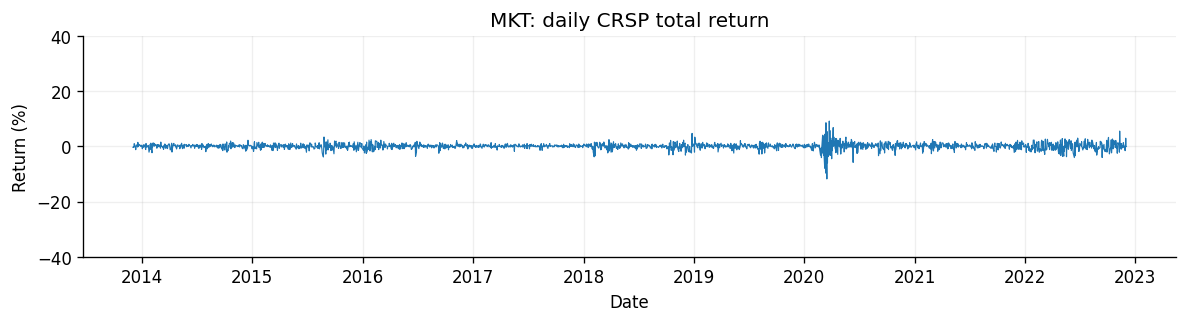

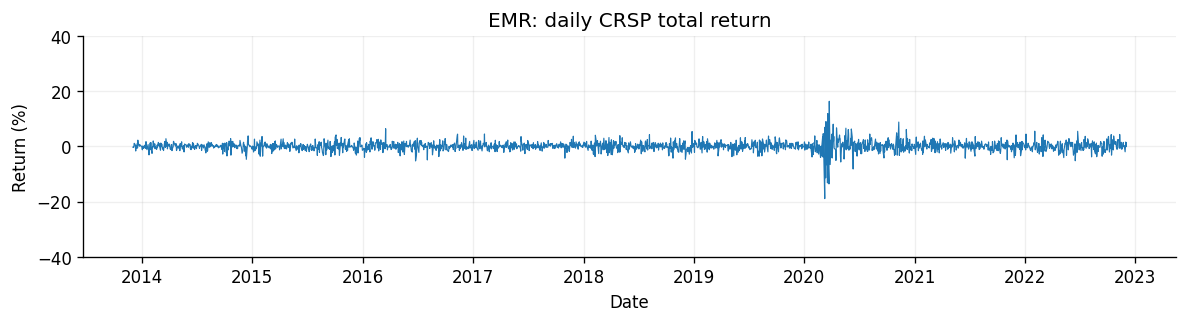

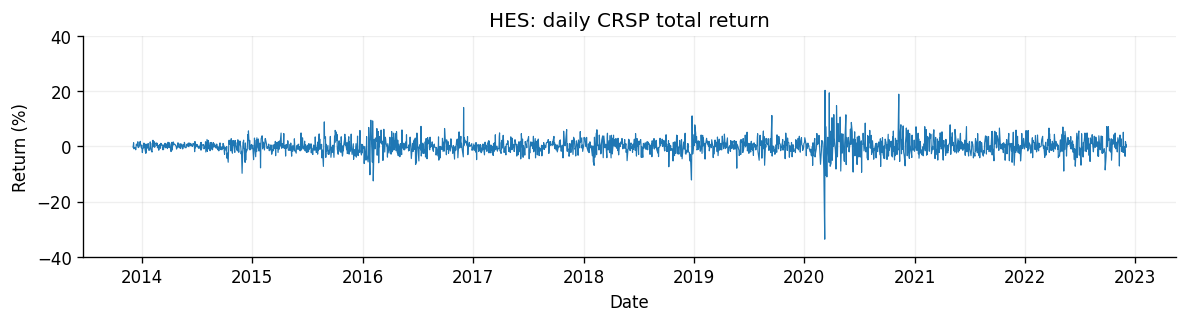

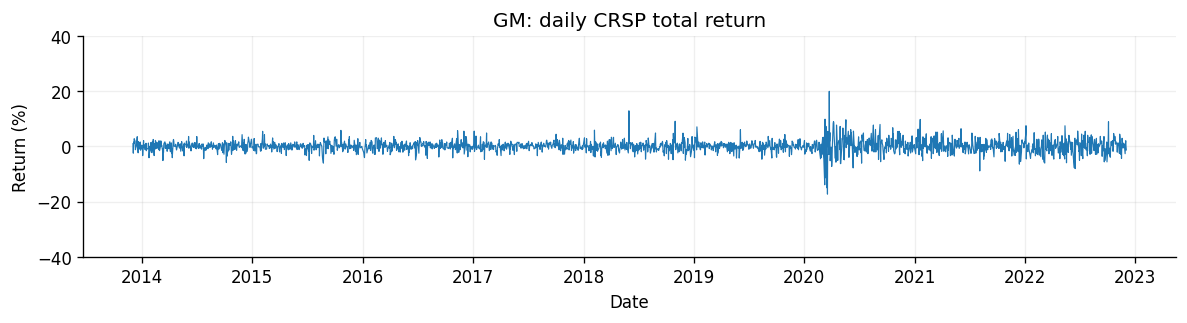

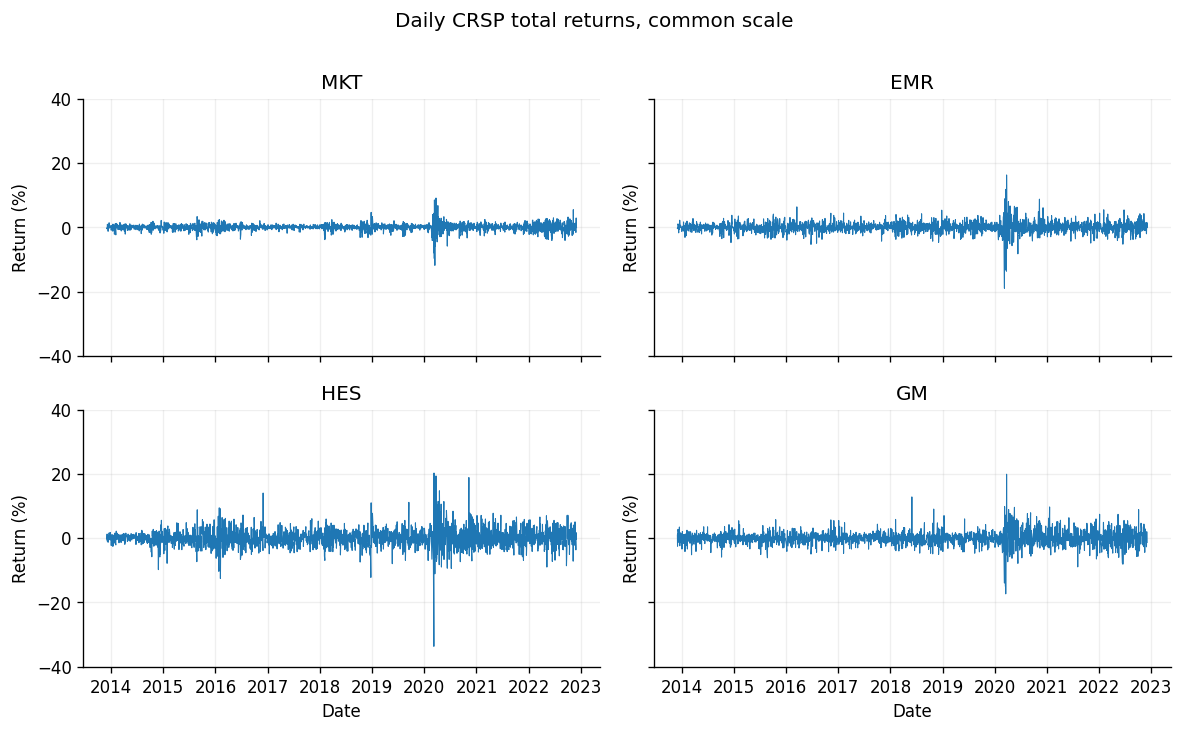

Peak common 20-day volatility score: 2020-04-02


In [5]:
def descriptive_stats(x):
    """Sample mean, standard deviation, skewness and excess kurtosis."""
    a=np.asarray(x,float)
    return {'N':a.size,'Mean':a.mean(),'Std. Dev.':a.std(ddof=1),'Minimum':a.min(),'Maximum':a.max(),
            'Skewness':stats.skew(a,bias=False),'Excess Kurtosis':stats.kurtosis(a,fisher=True,bias=False)}

desc=pd.DataFrame({c:descriptive_stats(returns[c]) for c in returns}).T
desc.index.name='Series'
desc.to_csv(TAB_DIR/'descriptive_statistics.csv')
display(desc)

# Individual return histories.
for col in returns.columns:
    fig,ax=plt.subplots(figsize=(10,2.8))
    ax.plot(returns.index,100*returns[col],linewidth=0.7)
    ax.set_title(f'{col}: daily CRSP total return')
    ax.set_ylabel('Return (%)'); ax.set_xlabel('Date')
    ax.set_ylim(-40,40)  # common scale makes cross-series volatility easier to compare
    fig.tight_layout(); fig.savefig(FIG_DIR/f'P2a_{col}_returns.png',bbox_inches='tight'); plt.show()

# Compact 2x2 comparison panel on a common y-axis.
fig,axes=plt.subplots(2,2,figsize=(10,6),sharex=True,sharey=True)
for ax,col in zip(axes.ravel(),returns.columns):
    ax.plot(returns.index,100*returns[col],linewidth=0.65)
    ax.set_title(col); ax.set_ylim(-40,40); ax.set_ylabel('Return (%)')
for ax in axes[-1,:]: ax.set_xlabel('Date')
fig.suptitle('Daily CRSP total returns, common scale',y=1.01)
fig.tight_layout(); fig.savefig(FIG_DIR/'P2a_all_returns_panel.png',bbox_inches='tight'); plt.show()

rolling20=returns.rolling(20).std()
common_vol_score=(rolling20/rolling20.median()).mean(axis=1)
print('Peak common 20-day volatility score:', common_vol_score.idxmax().date())

## 2(b) — Empirical VaR and expected shortfall

Empirical VaR is the negative return at rank $\lceil T\alpha\rceil$ (Lecture 1); ES averages the $\lfloor T\alpha\rfloor$ worst returns (Lecture 2). We report both measures as positive losses.

In [6]:
def empirical_var_es(r, alpha):
    """Historical VaR/ES as positive losses using the course order-statistic conventions."""
    if not (0 < alpha < 1):
        raise ValueError('alpha must be in (0,1)')
    x=np.asarray(pd.Series(r).dropna(),float)
    if x.ndim != 1:
        raise ValueError('r must be 1-D')

    # Empirical quantile: observation ranked ceil(T*alpha).
    q=np.quantile(x,alpha,method='inverted_cdf')
    # Lecture 2 historical ES: average the floor(alpha*T) worst realized returns.
    k=int(np.floor(alpha*x.size))
    if k < 1:
        raise ValueError('alpha is too small for this sample to define historical ES')
    var=-q
    es=-np.sort(x)[:k].mean()
    return float(var),float(es)

rows=[]
for series in returns.columns:
    for alpha in (0.01,0.05):
        v,e=empirical_var_es(returns[series],alpha)
        rows.append({'Series':series,'alpha':alpha,'VaR':v,'ES':e})
empirical_risk=pd.DataFrame(rows).set_index(['Series','alpha'])
empirical_risk.to_csv(TAB_DIR/'empirical_var_es.csv')
display(empirical_risk)
HES_VAR_01,HES_ES_01=empirical_var_es(returns['HES'],0.01)
HES_VAR_05,HES_ES_05=empirical_var_es(returns['HES'],0.05)

VaR       ES
Series alpha                     
MKT    0.010000 0.032808 0.048120
       0.050000 0.016964 0.027877
EMR    0.010000 0.041600 0.067894
       0.050000 0.025597 0.039243
HES    0.010000 0.072124 0.101323
       0.050000 0.040523 0.061026
GM     0.010000 0.055556 0.079440
       0.050000 0.033700 0.049054

In [7]:
# How much does the March 9 HES crash contribute to historical ES?
# Re-estimate after excluding that observation, using the same ES definition.
hes_without_event = returns.loc[returns.index != HES_EXTREME_DATE, 'HES']
_, HES_ES_01_WITHOUT_EVENT = empirical_var_es(hes_without_event, 0.01)
es_var_ratio = empirical_risk['ES'] / empirical_risk['VaR']
print(f'HES 1% ES without March 9: {HES_ES_01_WITHOUT_EVENT:.3%}')
print(f'ES/VaR ratio across the four series and two tail levels: '
      f'{es_var_ratio.min():.2f} to {es_var_ratio.max():.2f}')

HES 1% ES without March 9: 8.930%
ES/VaR ratio across the four series and two tail levels: 1.40 to 1.64


## 2(c) — OLS-normal VaR for HES

We regress HES on contemporaneous market returns and calculate conditional normal VaR from the fitted means and OLS residual standard deviation. The March 9, 2020 HES return provides a direct diagnostic of the normal-tail assumption.

In [8]:
X=sm.add_constant(returns['MKT'])
model_hes=sm.OLS(returns['HES'],X).fit()

def ols_normal_var(results,p):
    """Conditional VaR implied by a fitted OLS model and normal residuals."""
    if not isinstance(results,(RegressionResults,RegressionResultsWrapper)):
        raise TypeError('results must be a statsmodels RegressionResults object')
    if not (0<p<1):
        raise ValueError('p must be in (0,1)')
    sigma=math.sqrt(results.scale)
    return -(results.fittedvalues + sigma*norm.ppf(p))

sigma_ols=math.sqrt(model_hes.scale)
ols_var_01=ols_normal_var(model_hes,0.01)
ols_var_05=ols_normal_var(model_hes,0.05)

ols_summary=pd.DataFrame({'Value':[
    model_hes.params['const'],model_hes.params['MKT'],model_hes.rsquared,sigma_ols,
    ols_var_01.mean(),ols_var_05.mean(),ols_var_01.loc[HES_EXTREME_DATE],ols_var_05.loc[HES_EXTREME_DATE]
]},index=['Intercept','Market beta','R-squared','Residual sigma','Mean VaR 1%','Mean VaR 5%',
         'Event-date VaR 1%','Event-date VaR 5%'])
ols_summary.to_csv(TAB_DIR/'ols_summary.csv'); display(ols_summary)

mu_extreme=model_hes.fittedvalues.loc[HES_EXTREME_DATE]
z_extreme=(HES_EXTREME_RETURN-mu_extreme)/sigma_ols
normal_extreme_probability=norm.cdf(z_extreme)
empirical_extreme_frequency=(returns['HES'] <= HES_EXTREME_RETURN).mean()
actual_minus_event_var = (-HES_EXTREME_RETURN) - ols_var_01.loc[HES_EXTREME_DATE]
extreme_probability=pd.DataFrame({'Value':[HES_EXTREME_RETURN,returns.loc[HES_EXTREME_DATE,'MKT'],mu_extreme,z_extreme,
                                          normal_extreme_probability,empirical_extreme_frequency,
                                          ols_var_01.loc[HES_EXTREME_DATE],actual_minus_event_var]},
    index=['HES return','Market return','OLS fitted HES return','Conditional z-score',
           'Normal downside probability','Empirical downside frequency','Event-date VaR 1%',
           'Actual loss minus event-date 1% VaR'])
extreme_probability.to_csv(TAB_DIR/'extreme_probability.csv')
# Preserve very small probabilities in scientific notation rather than displaying 0.000000.
extreme_display = extreme_probability.copy()
extreme_display['Value'] = extreme_display['Value'].map(
    lambda v: f'{v:.3e}' if 0 < abs(v) < 1e-6 else f'{v:.6f}'
)
display(extreme_display)
print(f'Conditional normal tail probability: {normal_extreme_probability:.3e}')

# Diagnose the direction of the 5% coverage failure: compare empirical residual quantiles
# with the normal cutoffs implied by the fitted residual standard deviation.
resid = model_hes.resid.to_numpy()
resid_tail = pd.DataFrame({
    'Empirical residual quantile': [np.quantile(resid,0.05,method='inverted_cdf'),
                                    np.quantile(resid,0.01,method='inverted_cdf')],
    'Normal residual quantile': [sigma_ols*norm.ppf(0.05), sigma_ols*norm.ppf(0.01)]
}, index=['5%','1%'])
resid_tail['Empirical minus normal'] = resid_tail['Empirical residual quantile'] - resid_tail['Normal residual quantile']
display(resid_tail)

,Value
Intercept,0.000117
Market beta,1.394604
R-squared,0.306289
Residual sigma,0.023595
Mean VaR 1%,0.054163
Mean VaR 5%,0.038084
Event-date VaR 1%,0.165388
Event-date VaR 5%,0.149308


,Value
HES return,-0.336685
Market return,-0.079317
OLS fitted HES return,-0.110499
Conditional z-score,-9.586350
Normal downside probability,4.563e-22
Empirical downside frequency,0.000441
Event-date VaR 1%,0.165388
Actual loss minus event-date 1% VaR,0.171297


Conditional normal tail probability: 4.563e-22


,Empirical residual quantile,Normal residual quantile,Empirical minus normal
5%,-0.034515,-0.038810,0.004295
1%,-0.059162,-0.054889,-0.004272


## 2(d) — Time-varying VaR

The conditional variance places equal weight on the OLS variance and the preceding day's squared OLS residual. The first day's variance equals the constant OLS estimate.

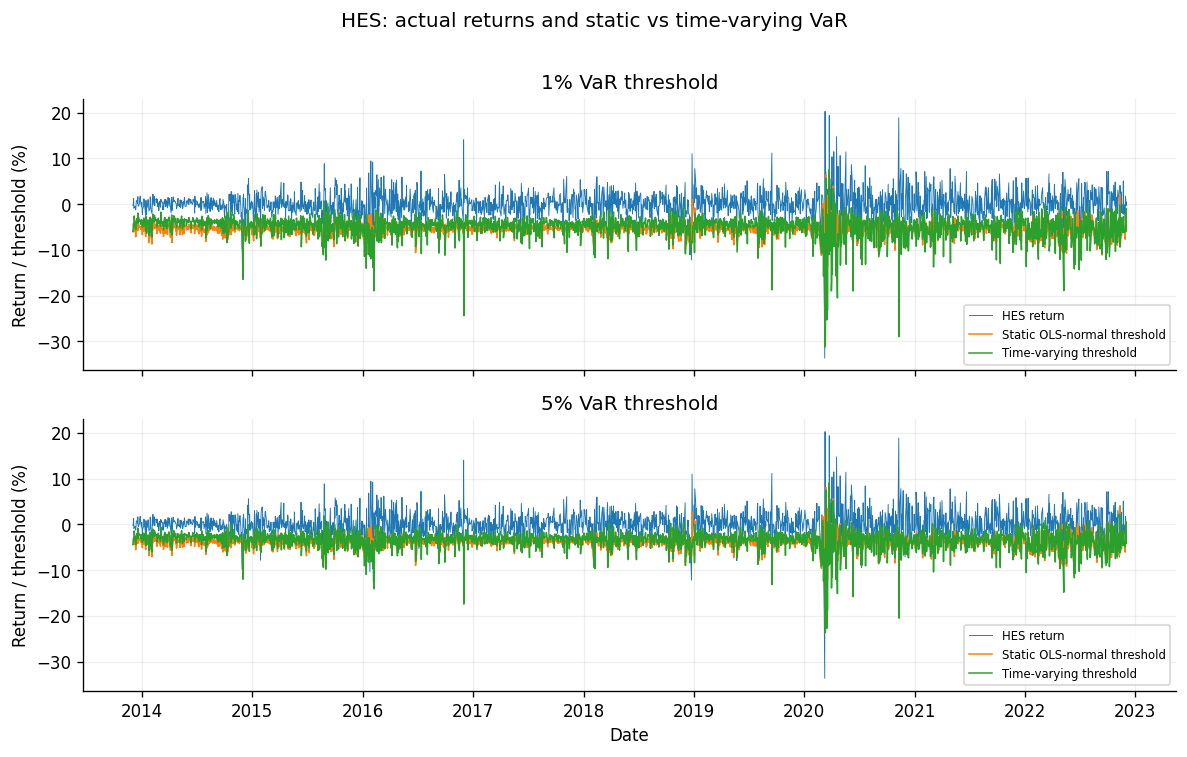

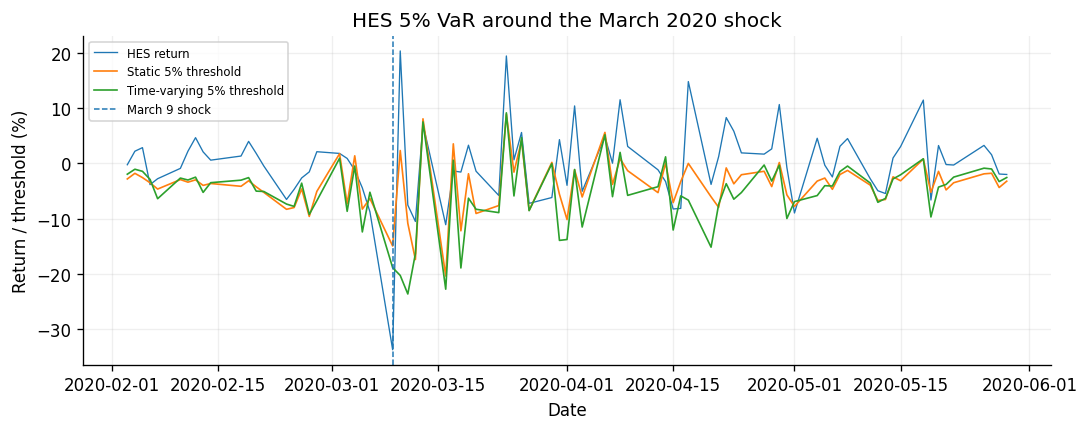

Largest time-varying residual sigma: 16.0806% on 2020-03-10


In [9]:
resid=model_hes.resid.to_numpy()
sigma2_tv=np.empty_like(resid)
sigma2_tv[0]=sigma_ols**2
# Each day's variance depends on yesterday's squared residual, not its own.
sigma2_tv[1:] = 0.5 * sigma_ols**2 + 0.5 * resid[:-1]**2
sigma_tv=np.sqrt(sigma2_tv)

def time_varying_var(results,sigma_t,p):
    """VaR series obtained by replacing static OLS sigma with the supplied conditional sigma_t."""
    return pd.Series(-(results.fittedvalues.to_numpy()+np.asarray(sigma_t)*norm.ppf(p)),index=results.fittedvalues.index)

tv_var_01=time_varying_var(model_hes,sigma_tv,0.01)
tv_var_05=time_varying_var(model_hes,sigma_tv,0.05)

# Static and time-varying risk thresholds over the entire sample.
fig,axes=plt.subplots(2,1,figsize=(10,6.2),sharex=True)
for ax,p,static,tv in [(axes[0],0.01,ols_var_01,tv_var_01),(axes[1],0.05,ols_var_05,tv_var_05)]:
    ax.plot(returns.index,100*returns['HES'],linewidth=0.55,label='HES return')
    ax.plot(returns.index,-100*static,linewidth=0.9,label='Static OLS-normal threshold')
    ax.plot(returns.index,-100*tv,linewidth=0.9,label='Time-varying threshold')
    ax.set_title(f'{p:.0%} VaR threshold'); ax.set_ylabel('Return / threshold (%)')
    ax.legend(fontsize=7,loc='lower right')
axes[1].set_xlabel('Date')
fig.suptitle('HES: actual returns and static vs time-varying VaR',y=1.01)
fig.tight_layout(); fig.savefig(FIG_DIR/'P2d_HES_VaR_full.png',bbox_inches='tight'); plt.show()

# Zoomed 2020 panel makes the one-day lag in the variance response visible.
zoom = (returns.index >= '2020-02-01') & (returns.index <= '2020-05-31')
fig,ax=plt.subplots(figsize=(9.2,3.7))
ax.plot(returns.index[zoom],100*returns.loc[zoom,'HES'],linewidth=0.8,label='HES return')
ax.plot(returns.index[zoom],-100*ols_var_05.loc[zoom],linewidth=1.0,label='Static 5% threshold')
ax.plot(returns.index[zoom],-100*tv_var_05.loc[zoom],linewidth=1.0,label='Time-varying 5% threshold')
ax.axvline(HES_EXTREME_DATE,linestyle='--',linewidth=0.9,label='March 9 shock')
ax.set_title('HES 5% VaR around the March 2020 shock')
ax.set_ylabel('Return / threshold (%)'); ax.set_xlabel('Date'); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG_DIR/'P2d_HES_VaR_2020_zoom.png',bbox_inches='tight'); plt.show()

sigma_tv_series=pd.Series(sigma_tv,index=returns.index)
print('Largest time-varying residual sigma:',f'{sigma_tv_series.max():.4%}','on',sigma_tv_series.idxmax().date())

## 2(e) — Coverage of 5% VaR

We count returns strictly below the VaR threshold, then use the exact two-sided Binomial test to assess whether the violation rate is 5%.

In [10]:
def coverage_test(r,var,p):
    """Exact Binomial coverage test for hit indicator r_t < -VaR_t."""
    x=np.asarray(r,float)
    v=np.asarray(var,float)
    # Strict inequality matters when an empirical VaR equals one observed return exactly.
    hits=(x < -v) if v.ndim else (x < -float(v))
    s1=int(hits.sum())
    return {'violations':s1,'n':x.size,'rate':s1/x.size,
            'p_value':stats.binomtest(s1,x.size,p).pvalue,'hits':hits.astype(int)}

cov_emp=coverage_test(returns['HES'],HES_VAR_05,0.05)
cov_ols=coverage_test(returns['HES'],ols_var_05.to_numpy(),0.05)
coverage_table=pd.DataFrame([
    {'Model':'Empirical','Violations':cov_emp['violations'],'n':cov_emp['n'],'Violation rate':cov_emp['rate'],'Exact Binomial p':cov_emp['p_value']},
    {'Model':'OLS normal','Violations':cov_ols['violations'],'n':cov_ols['n'],'Violation rate':cov_ols['rate'],'Exact Binomial p':cov_ols['p_value']}
]).set_index('Model')
coverage_table.to_csv(TAB_DIR/'coverage.csv'); display(coverage_table)
print('Violation rule: return < -VaR (strict inequality).')

,Violations,n,Violation rate,Exact Binomial p
Model,,,,
Empirical,113,2268,0.049824,1.000000
OLS normal,79,2268,0.034832,0.000611


Violation rule: return < -VaR (strict inequality).


## 2(f) — Independence of VaR violations

The Wald–Wolfowitz runs test examines whether violations are clustered or distributed independently over time. The p-value uses the large-sample normal approximation from Lecture 1.

In [11]:
def wald_wolfowitz_runs(binary):
    """Wald-Wolfowitz runs statistic and large-sample two-sided normal p-value (Lecture 1 A.36-A.37)."""
    x=np.asarray(binary,int)
    if x.ndim!=1 or not np.isin(x,[0,1]).all():
        raise ValueError('binary must be a 0/1 sequence')
    n=x.size; n1=int(x.sum()); n0=n-n1
    if n0==0 or n1==0:
        raise ValueError('both 0 and 1 must occur')
    R=1+int(np.sum(x[1:]!=x[:-1]))
    ER=1+2*n0*n1/n
    VR=2*n0*n1*(2*n0*n1-n)/(n**2*(n-1))
    z=(R-ER)/math.sqrt(VR)
    p=2*norm.sf(abs(z))
    return {'runs':R,'expected_runs':ER,'variance_runs':VR,'z':z,'p_value':p,'n0':n0,'n1':n1}

runs_emp=wald_wolfowitz_runs(cov_emp['hits'])
runs_ols=wald_wolfowitz_runs(cov_ols['hits'])
runs_table=pd.DataFrame([
    {'Model':'Empirical',**{k:runs_emp[k] for k in ['runs','expected_runs','z','p_value']}},
    {'Model':'OLS normal',**{k:runs_ols[k] for k in ['runs','expected_runs','z','p_value']}}
]).set_index('Model')
runs_table.to_csv(TAB_DIR/'runs.csv'); display(runs_table)

,runs,expected_runs,z,p_value
Model,,,,
Empirical,199,215.739859,-3.720304,0.000199
OLS normal,145,153.496473,-2.661542,0.007778


# Problem 3 - Simulations

## 3(a) — Student-t draws

We draw 200 observations from t(3), t(10), and t(100) using a shared, uninterrupted PCG64 random-number stream and compare their sample moments and histograms.

,Mean,Variance,Skewness,Excess Kurtosis,Theoretical variance,Theoretical excess kurtosis
df,,,,,,
3,-0.201057,2.294541,-1.014715,5.896943,3.000000,inf
10,0.087315,1.070049,0.161519,0.371986,1.250000,1.000000
100,-0.000306,0.887744,-0.242203,0.096685,1.020408,0.062500


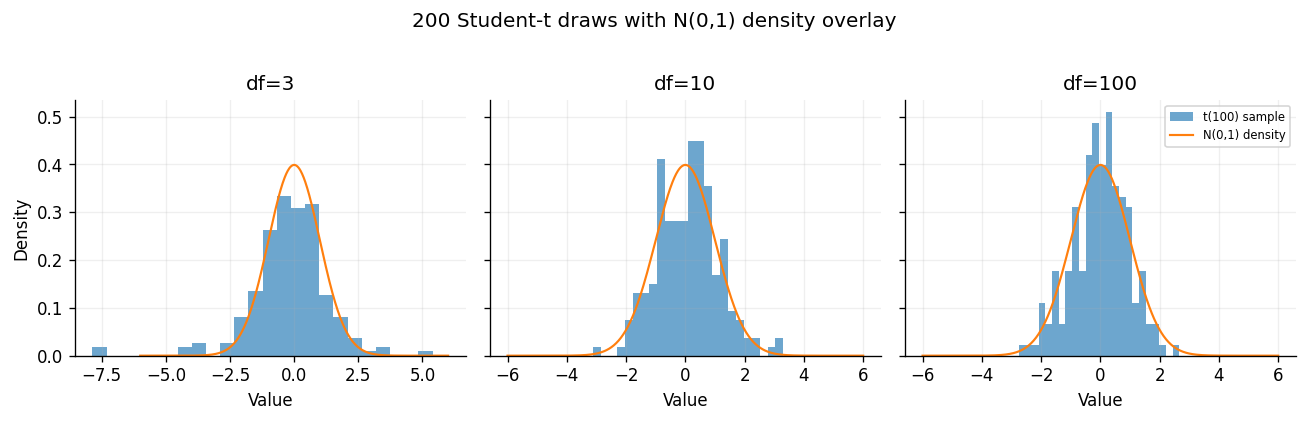

In [12]:
def Q3_t(bg,degrees):
    """Return 200 i.i.d. Student-t draws while advancing the supplied BitGenerator state."""
    if not isinstance(bg,np.random.BitGenerator):
        raise TypeError('bg must be a NumPy BitGenerator')
    if int(degrees)!=degrees or degrees<=0:
        raise ValueError('degrees must be a positive integer')
    return np.random.Generator(bg).standard_t(int(degrees),size=200)

# One BitGenerator instance is intentionally shared across the three calls; we never reseed inside Q3_t.
bg_t=np.random.PCG64(SEED)
t3=Q3_t(bg_t,3); t10=Q3_t(bg_t,10); t100=Q3_t(bg_t,100)

def moments(x):
    a=np.asarray(x,float)
    return {'Mean':a.mean(),'Variance':a.var(ddof=1),'Skewness':stats.skew(a,bias=False),
            'Excess Kurtosis':stats.kurtosis(a,fisher=True,bias=False)}

t_moments=pd.DataFrame({3:moments(t3),10:moments(t10),100:moments(t100)}).T
t_moments.index.name='df'
t_moments['Theoretical variance']=[3/(3-2),10/(10-2),100/(100-2)]
t_moments['Theoretical excess kurtosis']=[np.inf,6/(10-4),6/(100-4)]
t_moments.to_csv(TAB_DIR/'q3_t_moments.csv'); display(t_moments)

xx=np.linspace(-6,6,600)
fig,axes=plt.subplots(1,3,figsize=(11,3.4),sharey=True)
for ax,df_,sample in zip(axes,[3,10,100],[t3,t10,t100]):
    ax.hist(sample,bins=24,density=True,alpha=0.65,label=f't({df_}) sample')
    ax.plot(xx,norm.pdf(xx),linewidth=1.3,label='N(0,1) density')
    ax.set_title(f'df={df_}'); ax.set_xlabel('Value')
axes[0].set_ylabel('Density'); axes[-1].legend(fontsize=7)
fig.suptitle('200 Student-t draws with N(0,1) density overlay',y=1.02)
fig.tight_layout(); fig.savefig(FIG_DIR/'P3a_t_hist_panel.png',bbox_inches='tight'); plt.show()

In [13]:
# Theoretical tails help explain why 200 observations may obscure t(10)'s heavy tails.
T10_TAIL_EXPECTED = 200 * 2 * stats.t.sf(3, df=10)
NORMAL_TAIL_EXPECTED = 200 * 2 * norm.sf(3)
T100_EXCESS_KURTOSIS = 6 / (100 - 4)
print(f'Expected observations outside ±3 in 200 t(10) draws: {T10_TAIL_EXPECTED:.3f}')
print(f'Expected observations outside ±3 in 200 N(0,1) draws: {NORMAL_TAIL_EXPECTED:.3f}')
print(f'Theoretical excess kurtosis of t(100): {T100_EXCESS_KURTOSIS:.4f}')

Expected observations outside ±3 in 200 t(10) draws: 2.669
Expected observations outside ±3 in 200 N(0,1) draws: 0.540
Theoretical excess kurtosis of t(100): 0.0625


## 3(b) — Sampling with and without replacement

Bootstrap sampling allows observations to repeat; a shuffle without replacement preserves the empirical distribution and changes only the order.

In [14]:
def Q3_Sample(bg,a,r):
    """Draw a same-size sample with replacement (bootstrap) or without replacement (shuffle)."""
    if not isinstance(bg,np.random.BitGenerator):
        raise TypeError('bg must be a NumPy BitGenerator')
    x=np.asarray(a)
    if x.ndim!=1:
        raise ValueError('a must be 1-D')
    rng=np.random.Generator(bg)
    return rng.choice(x,size=x.size,replace=True) if bool(r) else rng.permutation(x)

demo=np.array([-0.10,-0.02,0.00,0.01,0.03])
bg_demo=np.random.PCG64(SEED)
demo_replace=Q3_Sample(bg_demo,demo,True)
demo_shuffle=Q3_Sample(bg_demo,demo,False)
print('Original:        ',demo)
print('With replacement:',demo_replace)
print('Without repl.:   ',demo_shuffle)

Original:         [-0.1  -0.02  0.    0.01  0.03]
With replacement: [ 0.03 -0.1  -0.02 -0.1   0.  ]
Without repl.:    [-0.02  0.    0.01  0.03 -0.1 ]


## 3(c) — Normal probability plots

We compare the t(3), t(100), and HES samples with N(0,1), then standardize HES to check whether departures remain after removing the location and scale mismatch.

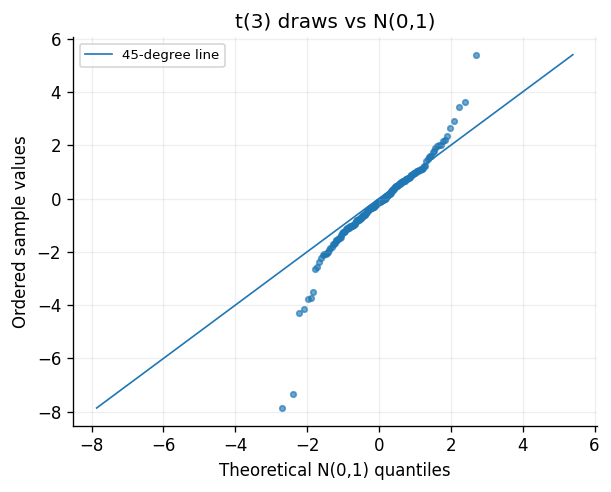

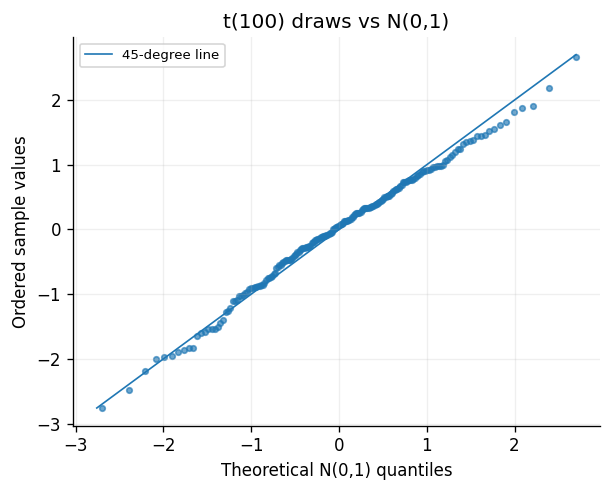

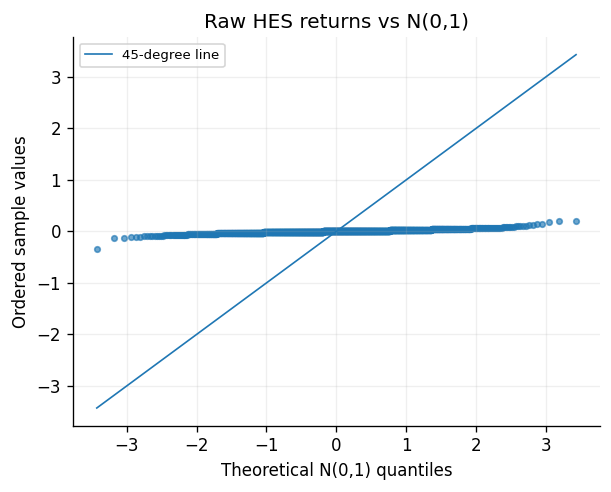

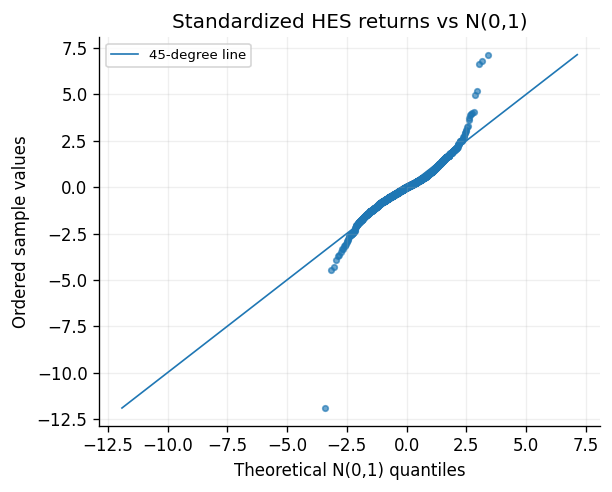

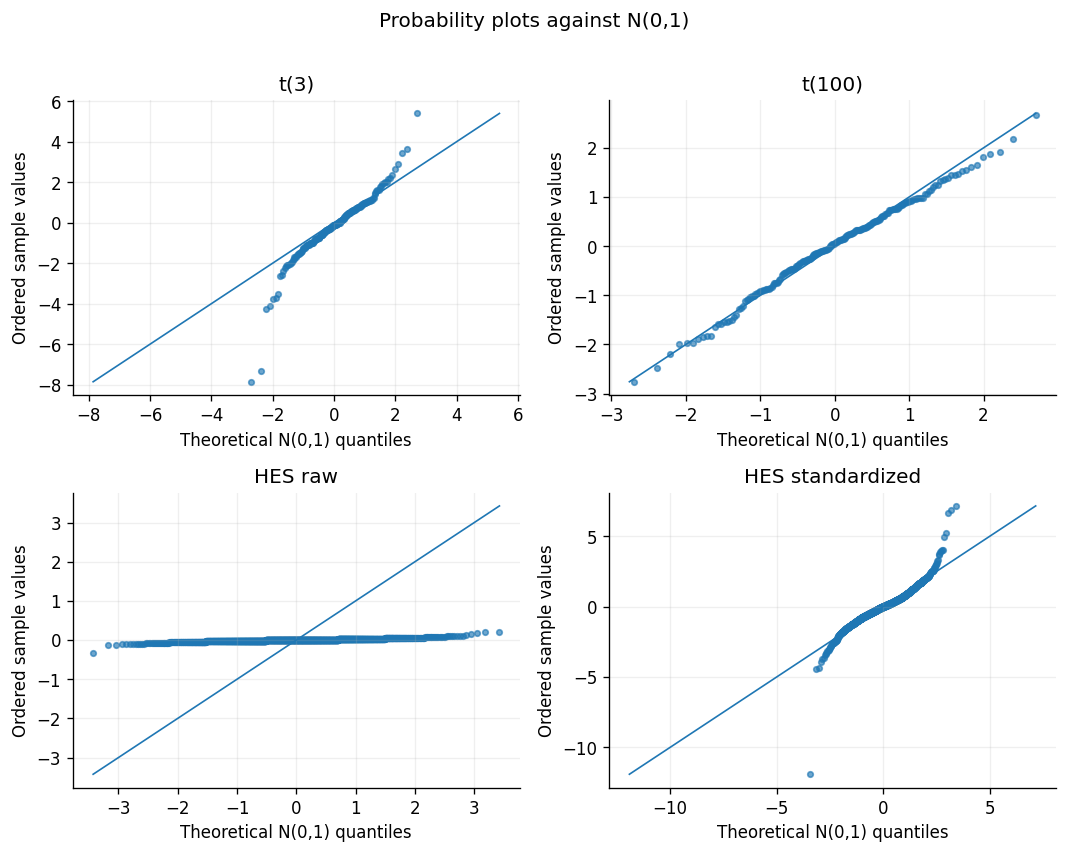

In [15]:
def Q3_ProbPlot(s,title=None,savepath=None,ax=None):
    """Probability plot of a supplied 1-D sample against the fully specified N(0,1) distribution."""
    x=np.asarray(s,float)
    if x.ndim!=1:
        raise ValueError('s must be 1-D')
    osm,osr=stats.probplot(x,dist='norm',fit=False)
    own_ax = ax is None
    if own_ax:
        fig,ax=plt.subplots(figsize=(5.2,4.2))
    ax.scatter(osm,osr,s=11,alpha=0.65)
    lo=min(np.min(osm),np.min(osr)); hi=max(np.max(osm),np.max(osr))
    ax.plot([lo,hi],[lo,hi],linewidth=1.0,label='45-degree line')
    ax.set_xlabel('Theoretical N(0,1) quantiles'); ax.set_ylabel('Ordered sample values')
    if title: ax.set_title(title)
    if own_ax:
        ax.legend(fontsize=8); fig.tight_layout()
        if savepath: fig.savefig(savepath,bbox_inches='tight')
        plt.show()

# Separate probability plots for each series.
Q3_ProbPlot(t3,'t(3) draws vs N(0,1)',FIG_DIR/'P3c_t3_probplot.png')
Q3_ProbPlot(t100,'t(100) draws vs N(0,1)',FIG_DIR/'P3c_t100_probplot.png')
Q3_ProbPlot(returns['HES'].to_numpy(),'Raw HES returns vs N(0,1)',FIG_DIR/'P3c_HES_raw_probplot.png')

# Supplementary shape diagnostic from Lecture 1: standardize stock returns so location/scale do not mechanically drive rejection.
hes_z=(returns['HES']-returns['HES'].mean())/returns['HES'].std(ddof=1)
Q3_ProbPlot(hes_z,'Standardized HES returns vs N(0,1)',FIG_DIR/'P3c_HES_standardized_probplot.png')

# Compact 2x2 comparison panel.
fig,axes=plt.subplots(2,2,figsize=(9,7))
for ax,x,title in [
    (axes[0,0],t3,'t(3)'),(axes[0,1],t100,'t(100)'),
    (axes[1,0],returns['HES'].to_numpy(),'HES raw'),(axes[1,1],hes_z.to_numpy(),'HES standardized')]:
    Q3_ProbPlot(x,title=title,ax=ax)
fig.suptitle('Probability plots against N(0,1)',y=1.01)
fig.tight_layout(); fig.savefig(FIG_DIR/'P3c_probplot_panel.png',bbox_inches='tight'); plt.show()

## 3(d) — Kolmogorov–Smirnov rejection rates

For each sample, we draw 1,000 bootstrap resamples and test N(0,1) at 5%. The rejection frequency measures the behaviour of the test under this resampling design.

In [16]:
def Q3_KS(bg,a,T):
    """Bootstrap a fixed source sample and return the fraction of one-sample KS rejections at 5%."""
    if not isinstance(bg,np.random.BitGenerator):
        raise TypeError('bg must be a NumPy BitGenerator')
    if int(T)!=T or T<=0:
        raise ValueError('T must be a positive integer')
    x=np.asarray(a,float)
    if x.ndim!=1:
        raise ValueError('a must be 1-D')
    rejects=0
    for _ in range(int(T)):
        sample=Q3_Sample(bg,x,True)
        rejects += stats.kstest(sample,'norm').pvalue < 0.05
    return rejects/int(T)

normal_sample=np.random.Generator(np.random.PCG64(SEED)).standard_normal(200)
bg_ks=np.random.PCG64(SEED+1)
# Compare a normal sample, t(3) draws, and the raw HES series.
ks_required={
    'N(0,1) sample':Q3_KS(bg_ks,normal_sample,1000),
    't(3) sample':Q3_KS(bg_ks,t3,1000),
    'HES raw returns':Q3_KS(bg_ks,returns['HES'].to_numpy(),1000)
}
# Supplementary check: does HES still reject after removing its obvious location/scale mismatch with N(0,1)?
ks_standardized_hes=Q3_KS(bg_ks,hes_z.to_numpy(),1000)

ks_table=pd.DataFrame.from_dict(ks_required,orient='index',columns=['Bootstrap rejection rate'])
ks_table['Original-sample KS p-value']=[
    stats.kstest(normal_sample,'norm').pvalue,
    stats.kstest(t3,'norm').pvalue,
    stats.kstest(returns['HES'].to_numpy(),'norm').pvalue
]
ks_table.to_csv(TAB_DIR/'q3_ks.csv'); display(ks_table)
print(f'Supplementary standardized-HES bootstrap rejection rate: {ks_standardized_hes:.3%}')
print(f'Supplementary standardized-HES original KS p-value: {stats.kstest(hes_z,"norm").pvalue:.6g}')

,Bootstrap rejection rate,Original-sample KS p-value
"N(0,1) sample",0.174000,0.554802
t(3) sample,0.578000,0.095678
HES raw returns,1.000000,0.000000


Supplementary standardized-HES bootstrap rejection rate: 100.000%
Supplementary standardized-HES original KS p-value: 1.18383e-10


## 3(e) — Size, power, and consistency with probability plots

The bootstrap rejection rate under a fixed normal source can differ from 5% because we repeatedly resample one finite sample, not new independent normal observations. The t(3) probability plot shows tail departures even though its original-sample KS p-value is 0.0957; the test is not particularly sensitive to isolated extremes. The report discusses the implications for the OLS-normal VaR model.

In [17]:
# Compare theoretical t(3) and standard-normal CDFs: the KS test uses the
# maximum CDF difference, rather than a tail-only deviation.
from scipy.optimize import minimize_scalar
cdf_gap_opt = minimize_scalar(lambda x: -(norm.cdf(x) - stats.t.cdf(x, df=3)),
                              bounds=(0, 10), method='bounded')
KS_MAX_GAP = float(-cdf_gap_opt.fun)
KS_MAX_LOCATION = float(cdf_gap_opt.x)
KS_CRITICAL_APPROX = 1.36 / np.sqrt(len(t3))
print(f'Maximum theoretical CDF gap |F_t3-F_N|: {KS_MAX_GAP:.4f} '
      f'at |x| = {KS_MAX_LOCATION:.2f}')
print(f'Approximate 5% one-sample KS critical gap at n=200: {KS_CRITICAL_APPROX:.3f}')
print(f'Original t(3) sample KS p-value: {stats.kstest(t3, "norm").pvalue:.4f}')

Maximum theoretical CDF gap |F_t3-F_N|: 0.0493 at |x| = 1.67
Approximate 5% one-sample KS critical gap at n=200: 0.096
Original t(3) sample KS p-value: 0.0957


# Problem 4 - Combining simulations and VaR

## 4(a) — Bootstrapped HES VaR

We estimate the sampling distribution of empirical VaR using 10,000 same-size resamples for each tail probability.

In [18]:
def bootstrap_var_distribution(bg,r,alpha,B=10000):
    """Return B historical-VaR estimates from same-size bootstrap resamples of r."""
    if not isinstance(bg,np.random.BitGenerator):
        raise TypeError('bg must be a NumPy BitGenerator')
    if not (0<alpha<1):
        raise ValueError('alpha must be in (0,1)')
    if int(B)!=B or B<=0:
        raise ValueError('B must be a positive integer')
    x=np.asarray(pd.Series(r).dropna(),float)
    n=x.size
    k=int(np.ceil(alpha*n))-1  # Lecture 1 order-statistic VaR index, zero-based here.
    out=np.empty(int(B))
    for b in range(int(B)):
        sample=Q3_Sample(bg,x,True)
        out[b]=-np.partition(sample,k)[k]
    return out

bg_boot=np.random.PCG64(SEED+2)
boot_01=bootstrap_var_distribution(bg_boot,returns['HES'],0.01,10000)
boot_05=bootstrap_var_distribution(bg_boot,returns['HES'],0.05,10000)

boot_summary=pd.DataFrame({
    'Empirical point VaR':[HES_VAR_01,HES_VAR_05],
    'Bootstrap mean VaR':[boot_01.mean(),boot_05.mean()],
    'Bootstrap SD':[boot_01.std(ddof=1),boot_05.std(ddof=1)],
    'Skewness':[stats.skew(boot_01,bias=False),stats.skew(boot_05,bias=False)],
    'Excess Kurtosis':[stats.kurtosis(boot_01,fisher=True,bias=False),stats.kurtosis(boot_05,fisher=True,bias=False)]
},index=['alpha=1%','alpha=5%'])
boot_summary.to_csv(TAB_DIR/'bootstrap_summary.csv'); display(boot_summary)

,Empirical point VaR,Bootstrap mean VaR,Bootstrap SD,Skewness,Excess Kurtosis
alpha=1%,0.072124,0.072002,0.003602,0.580564,2.835314
alpha=5%,0.040523,0.040509,0.001293,0.032376,0.409887


## 4(b) — Sampling distribution of 5% VaR

The distribution of the 10,000 bootstrap estimates describes sampling uncertainty in the historical 5% VaR, not volatility in the stock itself.

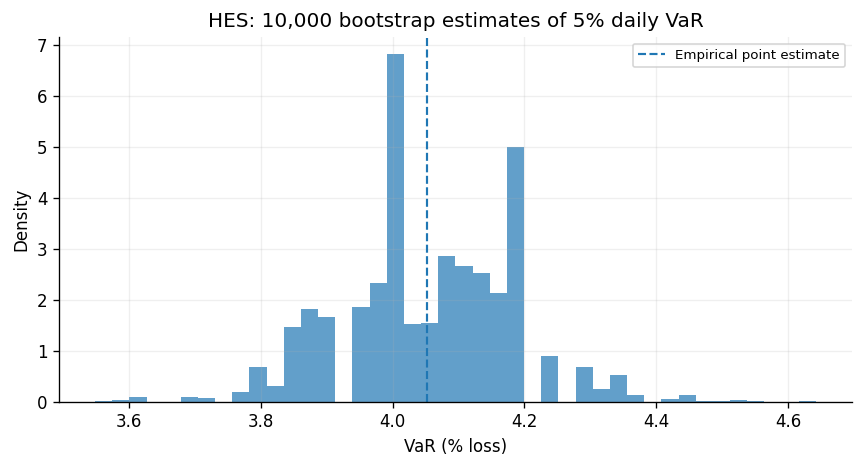

In [19]:
fig,ax=plt.subplots(figsize=(7.3,4.0))
ax.hist(100*boot_05,bins=42,density=True,alpha=0.7)
ax.axvline(100*HES_VAR_05,linestyle='--',linewidth=1.3,label='Empirical point estimate')
ax.set_title('HES: 10,000 bootstrap estimates of 5% daily VaR')
ax.set_xlabel('VaR (% loss)'); ax.set_ylabel('Density'); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR/'P4b_bootstrap_var5.png',bbox_inches='tight'); plt.show()

## 4(c) — Percentile confidence intervals

We use the 2.5th and 97.5th percentiles of each bootstrap sampling distribution to construct 95% confidence intervals.

In [20]:
ci_table=pd.DataFrame({
    '2.5%':[np.quantile(boot_01,0.025),np.quantile(boot_05,0.025)],
    '97.5%':[np.quantile(boot_01,0.975),np.quantile(boot_05,0.975)]
},index=['alpha=1%','alpha=5%'])
ci_table['Width']=ci_table['97.5%']-ci_table['2.5%']
ci_table.to_csv(TAB_DIR/'bootstrap_ci.csv'); display(ci_table)

,2.5%,97.5%,Width
alpha=1%,0.065827,0.081310,0.015483
alpha=5%,0.037961,0.043095,0.005134


In [21]:
# Translate the bootstrap interval into an illustrative $10 million risk position.
POSITION_VALUE = 10_000_000
var5_dollar_lower = POSITION_VALUE * ci_table.loc['alpha=5%', '2.5%']
var5_dollar_upper = POSITION_VALUE * ci_table.loc['alpha=5%', '97.5%']
print(f'5% VaR confidence interval on a $10 million position: '
      f'${var5_dollar_lower:,.0f} to ${var5_dollar_upper:,.0f}')

5% VaR confidence interval on a $10 million position: $379,610 to $430,950


## 4(d) — Comparison of VaR methods

We compare the unconditional empirical and bootstrap VaRs with the sample average of the market-conditional OLS-normal VaR. The estimates need not agree because they use different distributional assumptions.

In [22]:
comparison=pd.DataFrame({'VaR 5%':[
    HES_VAR_05,
    ols_var_05.mean(),
    boot_05.mean()
]},index=['Empirical','OLS-normal (mean conditional VaR)','Bootstrap mean'])
comparison.to_csv(TAB_DIR/'var_comparison.csv'); display(comparison)

,VaR 5%
Empirical,0.040523
OLS-normal (mean conditional VaR),0.038084
Bootstrap mean,0.040509


## Numerical summary

For convenient verification, the main statistics are also saved as `outputs/tables/summary.json`. Figures and intermediate tables are written to the corresponding `outputs` subfolders.

In [23]:
summary={
    'hes_extreme_date':str(HES_EXTREME_DATE.date()),'hes_extreme_return':float(HES_EXTREME_RETURN),
    'common_vol_peak':str(common_vol_score.idxmax().date()),
    'ols_intercept':float(model_hes.params['const']),'ols_beta':float(model_hes.params['MKT']),
    'ols_r2':float(model_hes.rsquared),'ols_sigma':float(sigma_ols),
    'ols_mean_var_01':float(ols_var_01.mean()),'ols_mean_var_05':float(ols_var_05.mean()),
    'event_mu':float(mu_extreme),'event_z':float(z_extreme),'event_normal_p':float(normal_extreme_probability),
    'event_empirical_freq':float(empirical_extreme_frequency),
    'event_var_01':float(ols_var_01.loc[HES_EXTREME_DATE]),'event_var_gap':float(actual_minus_event_var),
    'resid_emp_q05':float(resid_tail.loc['5%','Empirical residual quantile']),
    'resid_norm_q05':float(resid_tail.loc['5%','Normal residual quantile']),
    'resid_emp_q01':float(resid_tail.loc['1%','Empirical residual quantile']),
    'resid_norm_q01':float(resid_tail.loc['1%','Normal residual quantile']),
    'tv_sigma_max':float(sigma_tv_series.max()),'tv_sigma_max_date':str(sigma_tv_series.idxmax().date()),
    'coverage_emp_p':float(cov_emp['p_value']),'coverage_ols_p':float(cov_ols['p_value']),
    'coverage_emp_n':int(cov_emp['violations']),'coverage_ols_n':int(cov_ols['violations']),
    'runs_emp_p':float(runs_emp['p_value']),'runs_ols_p':float(runs_ols['p_value']),
    'runs_emp':int(runs_emp['runs']),'runs_ols':int(runs_ols['runs']),
    'runs_emp_expected':float(runs_emp['expected_runs']),'runs_ols_expected':float(runs_ols['expected_runs']),
    'ks_normal':float(ks_required['N(0,1) sample']),'ks_t3':float(ks_required['t(3) sample']),
    'ks_hes_raw':float(ks_required['HES raw returns']),'ks_hes_standardized':float(ks_standardized_hes),
    'ks_p_normal':float(stats.kstest(normal_sample,'norm').pvalue),
    'ks_p_t3':float(stats.kstest(t3,'norm').pvalue),
    'ks_p_hes_raw':float(stats.kstest(returns['HES'].to_numpy(),'norm').pvalue),
    'ks_p_hes_standardized':float(stats.kstest(hes_z,'norm').pvalue),
    'boot01_skew':float(stats.skew(boot_01,bias=False)),'boot01_kurt':float(stats.kurtosis(boot_01,fisher=True,bias=False)),
    'boot05_skew':float(stats.skew(boot_05,bias=False)),'boot05_kurt':float(stats.kurtosis(boot_05,fisher=True,bias=False))
}
summary.update({
    'sample_n': int(len(returns)),
    'hes_es_01_without_event': float(HES_ES_01_WITHOUT_EVENT),
    'es_var_ratio_min': float(es_var_ratio.min()),
    'es_var_ratio_max': float(es_var_ratio.max()),
    'expected_t10_outside_3_in_200': float(T10_TAIL_EXPECTED),
    'expected_normal_outside_3_in_200': float(NORMAL_TAIL_EXPECTED),
    't100_theory_excess_kurtosis': float(T100_EXCESS_KURTOSIS),
    'ks_theoretical_gap': float(KS_MAX_GAP),
    'ks_theoretical_gap_location': float(KS_MAX_LOCATION),
    'ks_critical_approx': float(KS_CRITICAL_APPROX),
    'var5_dollar_lower_10m': float(var5_dollar_lower),
    'var5_dollar_upper_10m': float(var5_dollar_upper),
    'boot_mean_01': float(boot_01.mean()), 'boot_mean_05': float(boot_05.mean()),
    'ci_01_lower': float(ci_table.loc['alpha=1%', '2.5%']),
    'ci_01_upper': float(ci_table.loc['alpha=1%', '97.5%']),
    'ci_05_lower': float(ci_table.loc['alpha=5%', '2.5%']),
    'ci_05_upper': float(ci_table.loc['alpha=5%', '97.5%']),
    'empirical_risk': {
        series: {str(alpha): {'VaR': float(empirical_risk.loc[(series, alpha), 'VaR']),
                              'ES': float(empirical_risk.loc[(series, alpha), 'ES'])}
                 for alpha in (0.01, 0.05)}
        for series in ('MKT', 'EMR', 'HES', 'GM')
    },
})
with open(TAB_DIR/'summary.json','w') as f: json.dump(summary,f,indent=2)
print('Saved summary to outputs/tables/summary.json')

Saved summary to outputs/tables/summary.json


## Data sources and assistance

We obtained the CRSP extracts through WRDS and used the methods described in Lectures 1 and 2. We used ChatGPT to assist with drafting and debugging Python code and reviewing presentation; we checked the calculations and interpretations ourselves. Bibliographic details appear in the accompanying report.